In [2]:
print("welcome to heart health chatbot project!")

welcome to heart health chatbot project!


In [3]:
import sys
print("python version:")
print(sys.version)
print("\npython executable:")
print(sys.executable)

python version:
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]

python executable:
C:\Users\JV\anaconda3\python.exe


In [1]:
%pip install pandas numpy matplotlib scikit-learn sreamlit joblib

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sreamlit (from versions: none)
ERROR: No matching distribution found for sreamlit


In [3]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import streamlit as st
import joblib
print("All required libraries imported successfully!")
print("scikit-learn version:", sklearn.__version__)

All required libraries imported successfully!
scikit-learn version: 1.9.0


In [6]:
project_name = "Heart Health Chatbot"
libraries_ready = True

print("Project:", project_name)
print("Libraries ready:", libraries_ready)
print("Type of project_name:", type(project_name))
print("Type of libraries_ready:", type(libraries_ready))


Project: Heart Health Chatbot
Libraries ready: True
Type of project_name: <class 'str'>
Type of libraries_ready: <class 'bool'>


In [7]:
from pathlib import Path

print("Current working folder:")
print(Path.cwd())


Current working folder:
C:\Users\JV\Desktop


In [8]:

from pathlib import Path

data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

print("Data folder location:", data_folder.resolve())
print("Does the data folder exist?", data_folder.exists())


Data folder location: C:\Users\JV\Desktop\data
Does the data folder exist? True


In [9]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [10]:

from ucimlrepo import fetch_ucirepo

# Step 1: Retrieve the Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Step 2: Combine the input features and target column
heart_data = heart_disease.data.original.copy()

# Step 3: Save the data as a CSV file
csv_path = data_folder / "heart_disease.csv"
heart_data.to_csv(csv_path, index=False)

# Step 4: Confirm that the file was saved
print("Dataset downloaded and saved successfully!")
print("File location:", csv_path.resolve())
print("Number of rows and columns:", heart_data.shape)


Dataset downloaded and saved successfully!
File location: C:\Users\JV\Desktop\data\heart_disease.csv
Number of rows and columns: (303, 14)


In [11]:

import pandas as pd

# Load the saved CSV file
df = pd.read_csv(csv_path)

# Display the first five rows
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [12]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (303, 14)
Number of rows: 303
Number of columns: 14


In [13]:
print("Column names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

Column names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [15]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary

,Missing Count,Missing Percentage
age,0,0.00
sex,0,0.00
cp,0,0.00
trestbps,0,0.00
chol,0,0.00
fbs,0,0.00
restecg,0,0.00
thalach,0,0.00
exang,0,0.00
oldpeak,0,0.00


In [16]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [17]:
print("Target values:")
print(df["num"].value_counts(dropna=False).sort_index())

Target values:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


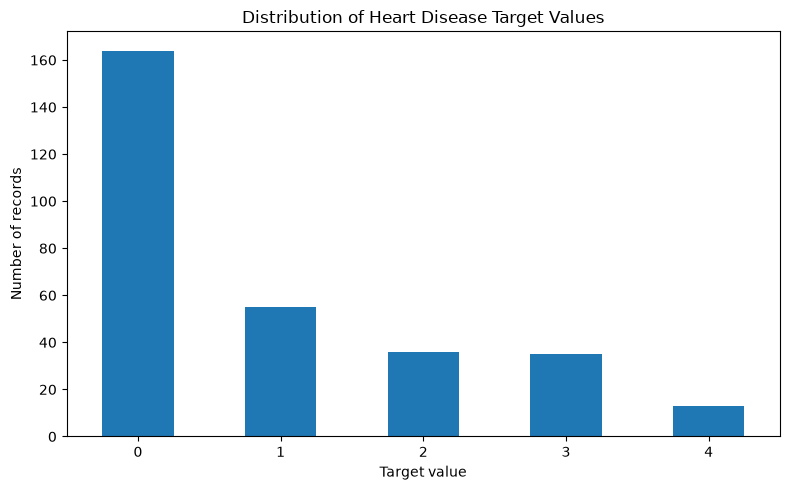

In [18]:
import matplotlib.pyplot as plt

target_counts = df["num"].value_counts().sort_index()

target_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Distribution of Heart Disease Target Values")
plt.xlabel("Target value")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
# Create a binary target column
df["target"] = (df["num"] > 0).astype(int)

# Compare the original and new target columns
df[["num", "target"]].head(10)

,num,target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


In [20]:
print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [21]:
# Select the input features
X = df.drop(columns=["num", "target"])

# Select the output we want to predict
y = df["target"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("\nInput feature names:")
print(X.columns.tolist())

Input features shape: (303, 13)
Target shape: (303,)

Input feature names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [22]:
print("Missing values in input features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in input features:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Missing values in target:
0


In [23]:
# Count missing values in each input column
missing_values = X.isnull().sum()

# Display only columns that have missing values
missing_values[missing_values > 0]

ca      4
thal    2
dtype: int64

In [24]:
# Check missing values in our input features
print("Missing values in each input column:")
print(X.isnull().sum())

# Check whether any target labels are missing
print("\nMissing target labels:")
print(y.isnull().sum())

Missing values in each input column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Missing target labels:
0


In [25]:
# Count records in each target class
print(y.value_counts().sort_index())

# Display the percentage of records in each class
print("\nPercentage of records in each class:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

target
0    164
1    139
Name: count, dtype: int64

Percentage of records in each class:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


In [26]:
from sklearn.model_selection import train_test_split

# Divide the input features and target labels
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (242, 13)
Testing input shape: (61, 13)
Training target shape: (242,)
Testing target shape: (61,)


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Step 1: Create a pipeline
model_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Our machine-learning pipeline is ready!")

Our machine-learning pipeline is ready!


In [30]:
# Train the pipeline using our training data
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


C:\Users\JV\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [31]:
# Generate predictions for the testing data
y_pred = model_pipeline.predict(X_test)

print("First 10 predicted labels:")
print(y_pred[:10])

First 10 predicted labels:
[0 1 0 0 1 0 0 0 1 0]


In [32]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", round(accuracy * 100, 2), "%")

Model accuracy: 86.89 %


Confusion matrix:
[[27  6]
 [ 2 26]]


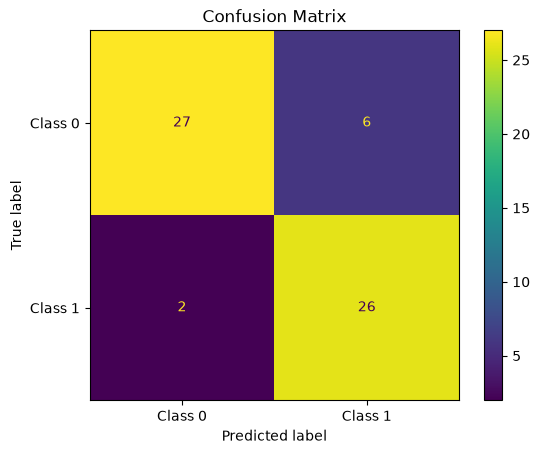

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare actual labels with predicted labels
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion matrix:")
print(cm)

# Display the matrix as a chart
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

display.plot()
plt.title("Confusion Matrix")
plt.show()

In [34]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0
))

              precision    recall  f1-score   support

     Class 0       0.93      0.82      0.87        33
     Class 1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



In [35]:
from pathlib import Path

model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

print("Model folder:", model_folder.resolve())

Model folder: C:\Users\JV\Desktop\models


In [36]:
import joblib

model_path = model_folder / "heart_disease_model.joblib"

joblib.dump(model_pipeline, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: C:\Users\JV\Desktop\models\heart_disease_model.joblib


In [37]:
loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

print("First 10 predictions:", loaded_predictions[:10])

Saved model loaded successfully!
First 10 predictions: [0 1 0 0 1 0 0 0 1 0]


In [40]:
%pip install gradio

Note: you may need to restart the kernel to use updated packages.


In [42]:
import gradio as gr

print("Gradio version:", gr.__version__)
print("Gradio imported successfully!")

Gradio version: 6.30.0
Gradio imported successfully!


In [43]:
import gradio as gr

def greet(name):
    return f"Hello, {name}! Welcome to the Heart Health Assistant."

demo = gr.Interface(
    fn=greet,
    inputs=gr.Textbox(label="Enter your name"),
    outputs=gr.Textbox(label="Assistant response"),
    title="Heart Health Assistant",
    description="Our first interactive web interface"
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [44]:
import gradio as gr

def summarize_inputs(age, cholesterol):
    return (
        f"Age entered: {age} years\n"
        f"Cholesterol entered: {cholesterol}"
    )

demo = gr.Interface(
    fn=summarize_inputs,
    inputs=[
        gr.Number(label="Age"),
        gr.Number(label="Cholesterol"),
    ],
    outputs=gr.Textbox(label="Input summary"),
    title="Heart Health Assistant",
    description="Practice interface for entering health measurements"
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset2.csv


In [45]:
import gradio as gr

def summarize_inputs(age, cholesterol):
    return (
        f"Age entered: {age} years\n"
        f"Cholesterol entered: {cholesterol}"
    )

demo = gr.Interface(
    fn=summarize_inputs,
    inputs=[
        gr.Number(label="Age"),
        gr.Number(label="Cholesterol"),
    ],
    outputs=gr.Textbox(label="Input summary"),
    title="Heart Health Assistant",
    description="Practice interface for entering health measurements"
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


In [46]:
print("Features expected by our model:")

for feature in X.columns:
    print("-", feature)

print("\nTotal number of features:", len(X.columns))

Features expected by our model:
- age
- sex
- cp
- trestbps
- chol
- fbs
- restecg
- thalach
- exang
- oldpeak
- slope
- ca
- thal

Total number of features: 13


In [47]:
import gradio as gr

def show_inputs(*values):
    return {
        feature: value
        for feature, value in zip(X.columns, values)
    }

inputs = [
    gr.Number(label=feature)
    for feature in X.columns
]

demo = gr.Interface(
    fn=show_inputs,
    inputs=inputs,
    outputs=gr.JSON(label="Submitted values"),
    title="Heart Health Assistant",
    description="Enter the 13 features required by our educational model."
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


In [48]:
# Display the feature descriptions from the dataset
print(heart_disease.variables[
    ["name", "description", "type"]
].to_string(index=False))

    name                                           description        type
     age                                                   NaN     Integer
     sex                                                   NaN Categorical
      cp                                                   NaN Categorical
trestbps resting blood pressure (on admission to the hospital)     Integer
    chol                                     serum cholestoral     Integer
     fbs                       fasting blood sugar > 120 mg/dl Categorical
 restecg                                                   NaN Categorical
 thalach                           maximum heart rate achieved     Integer
   exang                               exercise induced angina Categorical
 oldpeak    ST depression induced by exercise relative to rest     Integer
   slope                                                   NaN Categorical
      ca   number of major vessels (0-3) colored by flourosopy     Integer
    thal                 

In [49]:
# Display the feature documentation
heart_disease.variables[
    ["name", "description", "type"]
]

,name,description,type
0,age,NaN,Integer
1,sex,NaN,Categorical
2,cp,NaN,Categorical
3,trestbps,resting blood pressure (on admission to the ho...,Integer
4,chol,serum cholestoral,Integer
5,fbs,fasting blood sugar > 120 mg/dl,Categorical
6,restecg,NaN,Categorical
7,thalach,maximum heart rate achieved,Integer
8,exang,exercise induced angina,Categorical
9,oldpeak,ST depression induced by exercise relative to ...,Integer


In [8]:
import joblib
from pathlib import Path

model_path = Path("models") / "heart_disease_model.joblib"

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model expects these features:")
print(loaded_model.feature_names_in_)

Model loaded successfully!
Model expects these features:
['age' 'sex' 'cp' 'trestbps' 'chol' 'fbs' 'restecg' 'thalach' 'exang'
 'oldpeak' 'slope' 'ca' 'thal']


In [15]:
import pandas as pd

def predict_heart_disease(**inputs):
    # Arrange user inputs into a table
    input_data = pd.DataFrame([inputs])

    # Generate a prediction using our saved model
    prediction = loaded_model.predict(input_data)[0]

    # Convert the numeric class into a readable message
    if prediction == 0:
        result = "Predicted class: 0"
    else:
        result = "Predicted class: 1"

    return result

In [9]:
print(callable(predict_heart_disease))
print(loaded_model is not None)

True
True


In [13]:
print(loaded_model.feature_names_in_)

['age' 'sex' 'cp' 'trestbps' 'chol' 'fbs' 'restecg' 'thalach' 'exang'
 'oldpeak' 'slope' 'ca' 'thal']


In [14]:
sample_patient = {
    "age": 50,
    "sex": 1,
    "cp": 0,
    "trestbps": 130,
    "chol": 230,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.0,
    "slope": 1,
    "ca": 0,
    "thal": 2
}

result = predict_heart_disease(**sample_patient)
print(result)

Predicted class: 0


In [16]:
import pandas as pd

def predict_heart_disease(**inputs):
    # Arrange user inputs into a table
    input_data = pd.DataFrame([inputs])

    # Generate a prediction using our saved model
    prediction = loaded_model.predict(input_data)[0]

    # Convert the numeric class into a readable message
    if prediction == 0:
        result = "Predicted class: 0"
    else:
        result = "Predicted class: 1"

    return result

In [17]:
print("Number of required features:", len(loaded_model.feature_names_in_))
print("Feature names:", list(loaded_model.feature_names_in_))

Number of required features: 13
Feature names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [18]:
import gradio as gr

# Create one numeric input for every feature
inputs = [
    gr.Number(label=feature)
    for feature in loaded_model.feature_names_in_
]

# Connect the form to our prediction function
demo = gr.Interface(
    fn=predict_heart_disease,
    inputs=inputs,
    outputs=gr.Textbox(label="Model output"),
    title="Heart Health Assistant",
    description=(
        "Educational prototype using a heart-disease dataset. "
        "This output is not a medical diagnosis."
    )
)

demo.launch()

C:\Users\JV\anaconda3\Lib\site-packages\gradio\utils.py:1379: UserWarning: Expected 0 arguments for function <function predict_heart_disease at 0x000001AAF760F690>, received 13.
  warnings.warn(
C:\Users\JV\anaconda3\Lib\site-packages\gradio\utils.py:1387: UserWarning: Expected maximum 0 arguments for function <function predict_heart_disease at 0x000001AAF760F690>, received 13.
  warnings.warn(


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [19]:
import gradio as gr

print("Gradio version:", gr.__version__)

Gradio version: 6.30.0


In [2]:

import gradio as gr
from google import genai
from getpass import getpass

# 1. Enter your Gemini API key securely
GEMINI_API_KEY = getpass("Enter your Gemini API key: ")

# 2. Connect to Gemini
client = genai.Client(api_key=GEMINI_API_KEY)


# 3. Define the chatbot
def heart_health_chat(message, history):
    try:
        instructions = """
        You are a friendly, multilingual Heart Health Assistant.

        1. Understand and respond in the language the user uses,
           including Telugu, Hindi, Kannada, English, and other
           languages you can support.
        2. Follow the user's requested language if they specify one.
        3. Remember the conversation and answer follow-up questions.
        4. Explain heart-health concepts in simple language.
        5. Do not diagnose diseases or prescribe medication.
        6. Recommend qualified medical professionals for personal
           health concerns.
        7. For possible emergency symptoms, such as severe chest
           pain or difficulty breathing, advise urgent medical help.
        8. Be honest when you are uncertain.
        """

        conversation = []

        for user_msg, assistant_msg in (history or [])[-10:]:
            if user_msg:
                conversation.append(f"User: {user_msg}")
            if assistant_msg:
                conversation.append(f"Assistant: {assistant_msg}")

        prompt = (
            instructions
            + "\n\nPrevious conversation:\n"
            + ("\n".join(conversation) or "No previous messages.")
            + "\n\nCurrent question:\n"
            + message
            + "\n\nRespond naturally in the user's language."
        )

        response = client.models.generate_content(
            model="gemini-3.5-flash",
            contents=prompt
        )

        return response.text or (
            "Sorry, I couldn't generate a response. Please try again."
        )

    except Exception as e:
        print("Chatbot error:", type(e).__name__, str(e))
        return (
            "Sorry, I couldn't connect right now. "
            "Please try again."
        )


# 4. Create the chatbot interface
chatbot = gr.ChatInterface(
    fn=heart_health_chat,
    title="Heart Health Assistant",
    description=(
        "Ask heart-health questions in your preferred language. "
        "Get educational answers and ask follow-up questions."
    )
)

# 5. Launch the application
chatbot.launch()

ImportError: DLL load failed while importing _compute: An Application Control policy has blocked this file.

In [21]:

import gradio as gr

def heart_health_chat(message, history):
    question = message.lower()

    if "cholesterol" in question:
        return (
            "Cholesterol is a fatty substance in the blood. "
            "High levels of LDL cholesterol can increase the risk "
            "of cardiovascular disease. A blood test helps measure "
            "cholesterol levels."
        )

    elif "heart disease" in question:
        return (
            "Heart disease refers to several conditions affecting "
            "the heart. Our project uses a machine-learning model "
            "to estimate a class from selected health-record inputs. "
            "It cannot diagnose or rule out heart disease."
        )

    elif "blood pressure" in question:
        return (
            "Blood pressure measures the force of blood against "
            "artery walls. Persistently high blood pressure can "
            "increase cardiovascular risk."
        )

    elif "model" in question or "prediction" in question:
        return (
            "Our project uses a machine-learning model trained on "
            "the UCI Heart Disease dataset. It produces an educational "
            "prediction based on the supplied input features."
        )

    else:
        return (
            "I can currently answer a few basic questions about "
            "cholesterol, blood pressure, heart disease, and our model. "
            "Try asking about one of these topics."
        )

chatbot = gr.ChatInterface(
    fn=heart_health_chat,
    title="Heart Health Assistant",
    description="An educational chatbot for our AI heart-health project."
)

chatbot.launch()


* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


In [22]:
%pip install -U huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [24]:

from getpass import getpass

HF_TOKEN = getpass("enter your hugging face token:")

enter your hugging face token: ········


In [25]:

from huggingface_hub import InferenceClient

client = InferenceClient(
    model="Qwen/Qwen2.5-72B-Instruct",
    token=HF_TOKEN
)

response = client.chat_completion(
    messages=[
        {
            "role": "user",
            "content": "Explain cholesterol in simple words."
        }
    ],
    max_tokens=120
)

print(response.choices[0].message.content)


HfHubHTTPError: Client error '402 Payment Required' for url 'https://router.huggingface.co/v1/chat/completions' (Request ID: Root=1-6aca328b-39d31ad31535ebfd36456109;51c7c844-9de6-4069-b8aa-8bd752ea4ade)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

You have no remaining credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get monthly included credits.

In [26]:

from huggingface_hub import InferenceClient

client = InferenceClient(
    provider="publicai",
    token=HF_TOKEN
)

response = client.chat_completion(
    model="speakleash/Bielik-11B-v3.0-Instruct",
    messages=[
        {
            "role": "user",
            "content": "Explain cholesterol in simple words."
        }
    ],
    max_tokens=120
)

print(response.choices[0].message.content)


HfHubHTTPError: Client error '402 Payment Required' for url 'https://router.huggingface.co/publicai/v1/chat/completions' (Request ID: Root=1-6aca32e4-39f6bded392da3a8681365dd;7c63c825-36bb-45dc-91a8-c57670f775d6)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

You have no remaining credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get monthly included credits.

In [2]:
from getpass import getpass

GEMINI_API_KEY = getpass("Enter your Google AI Studio API key: ")

Enter your Google AI Studio API key:  ········


In [28]:
%pip install -U google-genai

   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 1.2/1.2 MB 10.6 MB/s  0:00:00

   ---------------------------------------- 0/5 [sniffio]
   -------- ------------------------------- 1/5 [pyasn1]
   -------- ------------------------------- 1/5 [pyasn1]
   -------- ------------------------------- 1/5 [pyasn1]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ---------------- ----------------------- 2/5 [pyasn1-modules]
   ------------------------ --------------- 3/5 [google-auth]
   ------------------------ --------------- 3/5 [google-auth]
   ------------------------ --------------- 3/5 

In [29]:

from google import genai

client = genai.Client(api_key=GEMINI_API_KEY)

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents="Explain cholesterol in simple words in 3 sentences."
)

print(response.text)


ClientError: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).', 'status': 'NOT_FOUND'}}

In [30]:

try:
    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents="Explain cholesterol in simple words."
    )
    print(response.text)

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", str(e))


Error type: ClientError
Error details: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).', 'status': 'NOT_FOUND'}}


In [31]:

response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain cholesterol in simple words in 3 sentences."
)

print(response.text)


ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [32]:

for model_info in client.models.list():
    if "generateContent" in (model_info.supported_actions or []):
        print(model_info.name)


models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/lyria-3.5
models/gemini

In [33]:

response = client.models.generate_content(
    model="gemini-3.5-flash",
    contents="Explain cholesterol in simple words in 3 sentences."
)

print(response.text)


Cholesterol is a waxy, fat-like substance in your blood that your body actually needs to build healthy cells. However, having too much of the "bad" type can create a sticky buildup inside your blood vessels. Over time, these clogs restrict blood flow and raise your risk for heart attacks and strokes.


In [34]:

import gradio as gr
from google import genai

# Create the AI client using your existing API key
client = genai.Client(api_key=GEMINI_API_KEY)

def heart_health_chat(message, history):
    try:
        response = client.models.generate_content(
            model="gemini-3.5-flash",
            contents=(
                "You are an educational heart-health assistant. "
                "Explain concepts in simple language. "
                "Do not diagnose diseases, prescribe medicines, "
                "or replace professional medical advice.\n\n"
                f"User question: {message}"
            )
        )

        return response.text or "I couldn't generate a response. Please try again."

    except Exception as e:
        print("Chatbot error:", type(e).__name__, str(e))
        return "Sorry, I couldn't get a response right now. Please try again."

chatbot = gr.ChatInterface(
    fn=heart_health_chat,
    title="Heart Health Assistant",
    description=(
        "Ask educational questions about heart health. "
        "This assistant does not provide medical diagnoses."
    )
)

chatbot.launch()


* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


In [78]:

import gradio as gr
import pandas as pd
import joblib
import torch
import torch.nn as nn
import numpy as np

from pathlib import Path
from google import genai


# =========================================================
# 1. LOAD THE SAVED HEART-DISEASE PREDICTION MODEL
# =========================================================

if "loaded_model" not in globals():
    loaded_model = joblib.load(
        Path("models") / "heart_disease_model.joblib"
    )


# =========================================================
# 2. CONNECT TO GEMINI
# =========================================================

client = genai.Client(api_key=GEMINI_API_KEY)


# =========================================================
# 3. LOAD THE ECG IMAGE MODEL
# =========================================================

class ECGImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


ecg_model = ECGImageClassifier()

ecg_model_path = Path("models") / "ecg_image_classifier.pth"

if ecg_model_path.exists():
    ecg_model.load_state_dict(
        torch.load(
            ecg_model_path,
            map_location="cpu",
            weights_only=True
        )
    )
    ecg_model.eval()
    ecg_model_ready = True
    print("ECG image model loaded successfully.")
else:
    ecg_model_ready = False
    print("ECG model file not found. ECG scoring is unavailable.")


# =========================================================
# 4. HEART-DISEASE PREDICTION FORM
# =========================================================

feature_names = list(loaded_model.feature_names_in_)

feature_labels = {
    "age": "Age (years)",
    "sex": "Sex (dataset code: 0 or 1)",
    "cp": "Chest pain type (dataset code: 1–4)",
    "trestbps": "Resting blood pressure (mm Hg)",
    "chol": "Serum cholesterol (mg/dl)",
    "fbs": "Fasting blood sugar code (0 or 1)",
    "restecg": "Resting ECG code (0–2)",
    "thalach": "Maximum heart rate achieved",
    "exang": "Exercise-induced angina (0 or 1)",
    "oldpeak": "Oldpeak (ST depression)",
    "slope": "ST slope code (1–3)",
    "ca": "Number of major vessels (0–3)",
    "thal": "Thal code (dataset-specific)",
}

defaults = {
    "age": 50,
    "sex": 1,
    "cp": 1,
    "trestbps": 120,
    "chol": 200,
    "fbs": 0,
    "restecg": 0,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.0,
    "slope": 2,
    "ca": 0,
    "thal": 3,
}


def predict_from_form(*values):
    try:
        input_data = pd.DataFrame(
            [values],
            columns=feature_names
        )

        prediction = int(loaded_model.predict(input_data)[0])

        if prediction == 0:
            result = (
                "Predicted class: 0 (negative class).\n"
                "The model classified these inputs into "
                "the dataset's negative class."
            )
        else:
            result = (
                "Predicted class: 1 (positive class).\n"
                "The model classified these inputs into "
                "the dataset's positive class."
            )

        return (
            f"{result}\n\n"
            "Educational demonstration only. "
            "This result is not a medical diagnosis."
        )

    except Exception as e:
        print("Prediction error:", type(e).__name__, str(e))
        return (
            "Prediction could not be completed. "
            "Please check the input values."
        )


# =========================================================
# 5. HEART-HEALTH CHATBOT
# =========================================================

def heart_health_chat(message, history):
    try:
        response = client.models.generate_content(
            model="gemini-3.5-flash",
            contents=(
                "You are an educational heart-health assistant. "
                "Explain concepts clearly and simply. Do not diagnose "
                "diseases or prescribe medication. Encourage professional "
                "medical care for personal health concerns. "
                "For possible emergency symptoms such as chest pain, "
                "severe breathlessness, or fainting, advise seeking "
                "urgent medical help.\n\n"
                f"User question: {message}"
            )
        )

        return response.text or "Please try asking your question again."

    except Exception as e:
        print("Chat error:", type(e).__name__, str(e))
        return "I couldn't get a response. Please try again."


# =========================================================
# 6. ECG IMAGE CLASSIFICATION DEMONSTRATION
# =========================================================

def inspect_ecg_image(image):
    if image is None:
        return "Please upload an ECG image first."

    if not ecg_model_ready:
        return (
            "The ECG model file was not found.\n"
            "Please train and save the ECG model first."
        )

    try:
        image_array = np.asarray(
            image.convert("RGB").resize((128, 128)),
            dtype=np.float32
        ) / 255.0

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        ).unsqueeze(0)

        ecg_model.eval()

        with torch.no_grad():
            logits = ecg_model(image_tensor)
            probability = torch.sigmoid(logits).item()

        return (
            "Experimental ECG model output\n"
            f"Score for label 1: {probability:.3f}\n\n"
            "This score comes from an experimental model trained "
            "on a small sample. It is not a reliable medical "
            "classification or diagnosis. Do not use it for "
            "medical decisions."
        )

    except Exception as e:
        print("ECG error:", type(e).__name__, str(e))
        return "Could not process this image. Please try another image."


# =========================================================
# 7. BUILD THE GRADIO APPLICATION
# =========================================================

with gr.Blocks(title="Heart Health Assistant") as app:

    gr.Markdown(
        "# Heart Health Assistant\n"
        "An educational project combining conversational AI, "
        "machine-learning prediction, and ECG image analysis."
    )

    # CHATBOT TAB
    with gr.Tab("Chatbot"):
        gr.ChatInterface(
            fn=heart_health_chat,
            title="Ask a Heart Health Question",
            description=(
                "Ask general educational questions about heart health."
            )
        )

    # PREDICTION TAB
    with gr.Tab("Prediction"):
        gr.Markdown(
            "### Heart Disease Prediction\n"
            "Enter the features using the dataset's numerical codes. "
            "This is an educational demonstration, not a diagnosis."
        )

        input_components = []

        for feature in feature_names:
            component = gr.Number(
                label=feature_labels.get(feature, feature),
                value=defaults.get(feature, 0)
            )
            input_components.append(component)

        predict_button = gr.Button("Run Prediction")

        prediction_output = gr.Textbox(
            label="Model Result",
            lines=4
        )

        predict_button.click(
            fn=predict_from_form,
            inputs=input_components,
            outputs=prediction_output
        )

    # ECG IMAGE TAB
    with gr.Tab("ECG Image"):
        gr.Markdown(
            "### ECG Image Analysis\n"
            "Upload an ECG image to obtain an experimental model score. "
            "This prototype is not clinically validated."
        )

        ecg_upload = gr.Image(
            type="pil",
            label="Upload ECG Image"
        )

        ecg_button = gr.Button("Analyze ECG Image")

        ecg_output = gr.Textbox(
            label="Experimental Model Output",
            lines=5
        )

        ecg_button.click(
            fn=inspect_ecg_image,
            inputs=ecg_upload,
            outputs=ecg_output
        )


# =========================================================
# 8. LAUNCH THE APPLICATION
# =========================================================

app.launch()


ECG image model loaded successfully.
* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


In [4]:
from pathlib import Path
import pandas as pd

csv_path = Path.home() / "Desktop" / "data" / "ptbxl_database.csv"

print("File exists:", csv_path.exists())
print("CSV path:", csv_path)

File exists: True
CSV path: C:\Users\JV\Desktop\data\ptbxl_database.csv


In [5]:
ptbxl_df = pd.read_csv(csv_path)

print("Dataset shape:", ptbxl_df.shape)

print("\nColumn names:")
print(ptbxl_df.columns.tolist())

ptbxl_df.head()

Dataset shape: (21799, 28)

Column names:
['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [6]:
print("ECG ID and diagnostic information:")

ptbxl_df[["ecg_id", "scp_codes", "report"]].head(10)

ECG ID and diagnostic information:


,ecg_id,scp_codes,report
0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",sinusrhythmus periphere niederspannung
1,2,"{'NORM': 80.0, 'SBRAD': 0.0}",sinusbradykardie sonst normales ekg
2,3,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
3,4,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
4,5,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
5,6,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
6,7,"{'NORM': 100.0, 'SR': 0.0}","sinusrhythmus linkstyp t abnormal, wahrscheinl..."
7,8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",sinusrhythmus linkstyp qrs(t) abnormal infe...
8,9,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
9,10,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg


In [7]:
from collections import Counter
import ast

all_codes = []

for codes in ptbxl_df["scp_codes"].dropna():
    if isinstance(codes, str):
        codes = ast.literal_eval(codes)

    all_codes.extend(codes.keys())

code_counts = Counter(all_codes)

print("Total unique diagnostic codes:", len(code_counts))
print("\nTop 20 diagnostic codes:")

pd.DataFrame(
    code_counts.most_common(20),
    columns=["Diagnostic Code", "Number of ECGs"]
)

Total unique diagnostic codes: 71

Top 20 diagnostic codes:


,Diagnostic Code,Number of ECGs
0,SR,16748
1,NORM,9514
2,ABQRS,3327
3,IMI,2676
4,ASMI,2357
5,LVH,2132
6,NDT,1825
7,LAFB,1623
8,AFIB,1514
9,ISC_,1272


In [8]:
print("Available diagnostic categories:")
print(ptbxl_df["scp_codes"].head(5).to_list())

print("\nNumber of ECG records:", len(ptbxl_df))
print("Number of unique ECG IDs:", ptbxl_df["ecg_id"].nunique())

Available diagnostic categories:
["{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}", "{'NORM': 80.0, 'SBRAD': 0.0}", "{'NORM': 100.0, 'SR': 0.0}", "{'NORM': 100.0, 'SR': 0.0}", "{'NORM': 100.0, 'SR': 0.0}"]

Number of ECG records: 21799
Number of unique ECG IDs: 21799


In [9]:
print("First 10 ECG record IDs:")
print(ptbxl_df["ecg_id"].head(10).to_list())

print("\nFirst 10 image paths:")
print(ptbxl_df["filename_lr"].head(10).to_list())

First 10 ECG record IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

First 10 image paths:
['records100/00000/00001_lr', 'records100/00000/00002_lr', 'records100/00000/00003_lr', 'records100/00000/00004_lr', 'records100/00000/00005_lr', 'records100/00000/00006_lr', 'records100/00000/00007_lr', 'records100/00000/00008_lr', 'records100/00000/00009_lr', 'records100/00000/00010_lr']


In [10]:
print("First 10 ECG IDs and their corresponding filenames:")

ptbxl_df[["ecg_id", "filename_lr", "filename_hr"]].head(10)

First 10 ECG IDs and their corresponding filenames:


,ecg_id,filename_lr,filename_hr
0,1,records100/00000/00001_lr,records500/00000/00001_hr
1,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,records100/00000/00003_lr,records500/00000/00003_hr
3,4,records100/00000/00004_lr,records500/00000/00004_hr
4,5,records100/00000/00005_lr,records500/00000/00005_hr
5,6,records100/00000/00006_lr,records500/00000/00006_hr
6,7,records100/00000/00007_lr,records500/00000/00007_hr
7,8,records100/00000/00008_lr,records500/00000/00008_hr
8,9,records100/00000/00009_lr,records500/00000/00009_hr
9,10,records100/00000/00010_lr,records500/00000/00010_hr


In [11]:
import ast
from collections import Counter

diagnostic_counts = Counter()

for codes in ptbxl_df["scp_codes"].dropna():
    if isinstance(codes, str):
        codes = ast.literal_eval(codes)

    diagnostic_counts.update(codes.keys())

pd.DataFrame(
    diagnostic_counts.most_common(15),
    columns=["Diagnostic Code", "Count"]
)

,Diagnostic Code,Count
0,SR,16748
1,NORM,9514
2,ABQRS,3327
3,IMI,2676
4,ASMI,2357
5,LVH,2132
6,NDT,1825
7,LAFB,1623
8,AFIB,1514
9,ISC_,1272


In [12]:
# Show the most common diagnostic codes
pd.DataFrame(
    diagnostic_counts.most_common(15),
    columns=["Diagnostic Code", "Count"]
)

,Diagnostic Code,Count
0,SR,16748
1,NORM,9514
2,ABQRS,3327
3,IMI,2676
4,ASMI,2357
5,LVH,2132
6,NDT,1825
7,LAFB,1623
8,AFIB,1514
9,ISC_,1272


In [13]:
# Display the columns needed to match ECG records and labels
print(ptbxl_df[["ecg_id", "scp_codes"]].head())

print("\nImage filename example:")
print(ptbxl_df[["ecg_id", "filename_hr"]].head())

   ecg_id                                 scp_codes
0       1  {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
1       2              {'NORM': 80.0, 'SBRAD': 0.0}
2       3                {'NORM': 100.0, 'SR': 0.0}
3       4                {'NORM': 100.0, 'SR': 0.0}
4       5                {'NORM': 100.0, 'SR': 0.0}

Image filename example:
   ecg_id                filename_hr
0       1  records500/00000/00001_hr
1       2  records500/00000/00002_hr
2       3  records500/00000/00003_hr
3       4  records500/00000/00004_hr
4       5  records500/00000/00005_hr


In [14]:
import ast

def get_diagnostic_codes(value):
    if isinstance(value, str):
        return ast.literal_eval(value)
    if isinstance(value, dict):
        return value
    return {}

ptbxl_df["diagnostic_codes"] = ptbxl_df["scp_codes"].apply(
    get_diagnostic_codes
)

ptbxl_df["has_norm_code"] = ptbxl_df["diagnostic_codes"].apply(
    lambda codes: "NORM" in codes
)

print(ptbxl_df["has_norm_code"].value_counts())

has_norm_code
False    12285
True      9514
Name: count, dtype: int64


In [15]:
print("ECGs with NORM code:")
print(ptbxl_df["has_norm_code"].sum())

print("\nECGs without NORM code:")
print((~ptbxl_df["has_norm_code"]).sum())

print("\nExamples of records with NORM:")
ptbxl_df.loc[
    ptbxl_df["has_norm_code"],
    ["ecg_id", "scp_codes"]
].head()

ECGs with NORM code:
9514

ECGs without NORM code:
12285

Examples of records with NORM:


,ecg_id,scp_codes
0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,"{'NORM': 100.0, 'SR': 0.0}"
3,4,"{'NORM': 100.0, 'SR': 0.0}"
4,5,"{'NORM': 100.0, 'SR': 0.0}"


In [16]:
label_summary = (
    ptbxl_df["has_norm_code"]
    .value_counts()
    .rename(index={True: "Has NORM annotation", False: "No NORM annotation"})
)

print(label_summary)

has_norm_code
No NORM annotation     12285
Has NORM annotation     9514
Name: count, dtype: int64


In [17]:
print("First 10 ECG IDs:")
print(ptbxl_df["ecg_id"].head(10).tolist())

print("\nCorresponding high-resolution signal paths:")
print(ptbxl_df["filename_hr"].head(10).tolist())

First 10 ECG IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Corresponding high-resolution signal paths:
['records500/00000/00001_hr', 'records500/00000/00002_hr', 'records500/00000/00003_hr', 'records500/00000/00004_hr', 'records500/00000/00005_hr', 'records500/00000/00006_hr', 'records500/00000/00007_hr', 'records500/00000/00008_hr', 'records500/00000/00009_hr', 'records500/00000/00010_hr']


In [18]:
print(
    ptbxl_df[
        ["ecg_id", "filename_hr", "filename_lr", "scp_codes"]
    ].head(10).to_string(index=False)
)

 ecg_id               filename_hr               filename_lr                                scp_codes
      1 records500/00000/00001_hr records100/00000/00001_lr {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
      2 records500/00000/00002_hr records100/00000/00002_lr             {'NORM': 80.0, 'SBRAD': 0.0}
      3 records500/00000/00003_hr records100/00000/00003_lr               {'NORM': 100.0, 'SR': 0.0}
      4 records500/00000/00004_hr records100/00000/00004_lr               {'NORM': 100.0, 'SR': 0.0}
      5 records500/00000/00005_hr records100/00000/00005_lr               {'NORM': 100.0, 'SR': 0.0}
      6 records500/00000/00006_hr records100/00000/00006_lr               {'NORM': 100.0, 'SR': 0.0}
      7 records500/00000/00007_hr records100/00000/00007_lr               {'NORM': 100.0, 'SR': 0.0}
      8 records500/00000/00008_hr records100/00000/00008_lr   {'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}
      9 records500/00000/00009_hr records100/00000/00009_lr               {'NORM': 100.0, '

In [19]:
# Check whether the image IDs match the metadata record IDs
print("First 10 metadata ECG IDs:")
print(ptbxl_df["ecg_id"].head(10).tolist())

print("\nFirst 10 high-resolution filenames:")
print(ptbxl_df["filename_hr"].head(10).tolist())

First 10 metadata ECG IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

First 10 high-resolution filenames:
['records500/00000/00001_hr', 'records500/00000/00002_hr', 'records500/00000/00003_hr', 'records500/00000/00004_hr', 'records500/00000/00005_hr', 'records500/00000/00006_hr', 'records500/00000/00007_hr', 'records500/00000/00008_hr', 'records500/00000/00009_hr', 'records500/00000/00010_hr']


In [20]:
# Create image filenames from the ECG record IDs
ptbxl_df["image_filename"] = (
    ptbxl_df["ecg_id"]
    .astype(int)
    .map(lambda x: f"{x:05d}_hr_1R.png")
)

print(
    ptbxl_df[
        ["ecg_id", "image_filename", "scp_codes"]
    ].head(10).to_string(index=False)
)

 ecg_id  image_filename                                scp_codes
      1 00001_hr_1R.png {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
      2 00002_hr_1R.png             {'NORM': 80.0, 'SBRAD': 0.0}
      3 00003_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      4 00004_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      5 00005_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      6 00006_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      7 00007_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      8 00008_hr_1R.png   {'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}
      9 00009_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
     10 00010_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}


In [21]:
%pip install -U huggingface_hub datasets

   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 6.8 MB/s  0:00:00
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ----- ---------------------------------- 3.7/29.2 MB 18.6 MB/s eta 0:00:02
   -------- ------------------------------- 6.6/29.2 MB 15.5 MB/s eta 0:00:02
   ------------ --------------------------- 9.2/29.2 MB 14.5 MB/s eta 0:00:02
   ---------------- ----------------------- 12.1/29.2 MB 14.3 MB/s eta 0:00:02
   -------------------- ------------------- 14.9/29.2 MB 14.1 MB/s eta 0:00:02
   ----------------------- ---------------- 17.3/29.2 MB 13.5 MB/s eta 0:00:01
   --------------------------- ------------ 19.9/29.2 MB 13.2 MB/s eta 0:00:01
   ------------------------------ --------- 22.3/29.2 MB 13.0 MB/s eta 0:00:01
   -------------------------------- ------- 24.1/29.2 MB 12.6 MB/s eta 0:00:01
   ---------------------------------- ----- 25.2/29.2 MB 12.2 MB/s eta 0:0

In [22]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "akshithamuthyalampally/GenECG"

files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Number of files listed:", len(files))
print("\nFirst 20 files:")
print(files[:20])

Number of files listed: 43601

First 20 files:
['.gitattributes', 'Dataset_A_ECGs_without_imperfections/00000/00001_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00002_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00003_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00004_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00005_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00006_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00007_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00008_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00009_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00010_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00011_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00012_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00013_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00014_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00015_hr_1R.png', 'Dat

In [23]:
from huggingface_hub import hf_hub_download
from pathlib import Path

repo_id = "akshithamuthyalampally/GenECG"

sample_path = hf_hub_download(
    repo_id=repo_id,
    repo_type="dataset",
    filename="Dataset_A_ECGs_without_imperfections/00000/00001_hr_1R.png"
)

print("Sample image downloaded to:")
print(sample_path)

C:\Users\JV\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\JV\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Dataset_A_ECGs_without_imperfections/000(…): reconstructing file:   0%|          |  0.00B / 99.9kB            

Dataset_A_ECGs_without_imperfections/000(…): downloading bytes:           |  0.00B            

Sample image downloaded to:
C:\Users\JV\.cache\huggingface\hub\datasets--akshithamuthyalampally--GenECG\snapshots\14e19daa342f5905a4d51dbbb01b2f25d858d0aa\Dataset_A_ECGs_without_imperfections\00000\00001_hr_1R.png


C:\Users\JV\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\JV\.cache\huggingface\hub\datasets--akshithamuthyalampally--GenECG. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Image size: (1397, 1029)
Image format: PNG


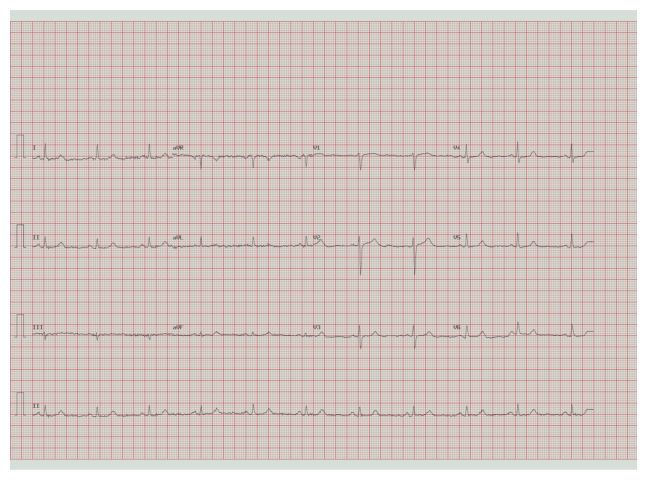

In [24]:
from PIL import Image
import matplotlib.pyplot as plt

ecg_image = Image.open(sample_path)

print("Image size:", ecg_image.size)
print("Image format:", ecg_image.format)

plt.figure(figsize=(14, 6))
plt.imshow(ecg_image)
plt.axis("off")
plt.show()

In [25]:
record = ptbxl_df.loc[ptbxl_df["ecg_id"] == 1]

if record.empty:
    print("No matching ECG ID found.")
else:
    print(record[["ecg_id", "scp_codes", "report"]].to_string(index=False))

 ecg_id                                scp_codes                                 report
      1 {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0} sinusrhythmus periphere niederspannung


In [26]:
print("Matching metadata record:")
print(
    ptbxl_df.loc[
        ptbxl_df["ecg_id"] == 1,
        ["ecg_id", "filename_hr", "scp_codes", "report"]
    ].to_string(index=False)
)

Matching metadata record:
 ecg_id               filename_hr                                scp_codes                                 report
      1 records500/00000/00001_hr {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0} sinusrhythmus periphere niederspannung


In [27]:
print("Smallest ECG ID:", ptbxl_df["ecg_id"].min())
print("Largest ECG ID:", ptbxl_df["ecg_id"].max())

print("\nFirst 10 ECG IDs:")
print(ptbxl_df["ecg_id"].head(10).tolist())

Smallest ECG ID: 1
Largest ECG ID: 21837

First 10 ECG IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [28]:
# Display the diagnostic codes for the first 10 records
for _, row in ptbxl_df.head(10).iterrows():
    print("ECG ID:", row["ecg_id"])
    print("Codes:", row["scp_codes"])
    print("-" * 40)

ECG ID: 1
Codes: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
----------------------------------------
ECG ID: 2
Codes: {'NORM': 80.0, 'SBRAD': 0.0}
----------------------------------------
ECG ID: 3
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------
ECG ID: 4
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------
ECG ID: 5
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------
ECG ID: 6
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------
ECG ID: 7
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------
ECG ID: 8
Codes: {'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}
----------------------------------------
ECG ID: 9
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------
ECG ID: 10
Codes: {'NORM': 100.0, 'SR': 0.0}
----------------------------------------


In [29]:
# Show the diagnostic code definitions from the metadata
for codes in ptbxl_df["scp_codes"].dropna().head(5):
    print(codes)
    print("-" * 40)

{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
----------------------------------------
{'NORM': 80.0, 'SBRAD': 0.0}
----------------------------------------
{'NORM': 100.0, 'SR': 0.0}
----------------------------------------
{'NORM': 100.0, 'SR': 0.0}
----------------------------------------
{'NORM': 100.0, 'SR': 0.0}
----------------------------------------


In [30]:
# Check how many metadata records have each ECG ID
print("Unique ECG IDs:", ptbxl_df["ecg_id"].nunique())
print("Duplicate ECG IDs:", ptbxl_df["ecg_id"].duplicated().sum())

# Show a few records with their image filenames
print(
    ptbxl_df[["ecg_id", "image_filename", "scp_codes"]]
    .head(10)
    .to_string(index=False)
)

Unique ECG IDs: 21799
Duplicate ECG IDs: 0
 ecg_id  image_filename                                scp_codes
      1 00001_hr_1R.png {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
      2 00002_hr_1R.png             {'NORM': 80.0, 'SBRAD': 0.0}
      3 00003_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      4 00004_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      5 00005_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      6 00006_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      7 00007_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
      8 00008_hr_1R.png   {'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}
      9 00009_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}
     10 00010_hr_1R.png               {'NORM': 100.0, 'SR': 0.0}


In [31]:
from pathlib import Path

ecg_image_folder = Path.home() / "Desktop" / "data" / "ecg_images"
ecg_image_folder.mkdir(parents=True, exist_ok=True)

print("ECG image folder created:", ecg_image_folder)

ECG image folder created: C:\Users\JV\Desktop\data\ecg_images


In [32]:
from pathlib import Path
import shutil

ecg_image_folder = Path.home() / "Desktop" / "data" / "ecg_images"
ecg_image_folder.mkdir(parents=True, exist_ok=True)

destination = ecg_image_folder / "sample_ecg.png"

shutil.copy2(sample_path, destination)

print("ECG image saved successfully!")
print("Location:", destination)
print("File exists:", destination.exists())

ECG image saved successfully!
Location: C:\Users\JV\Desktop\data\ecg_images\sample_ecg.png
File exists: True


In [35]:
%pip install -U torch torchvision scikit-learn pillow huggingface_hub pandas

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   - -------------------------------------- 3.1/124.1 MB 18.3 MB/s eta 0:00:07
   - -------------------------------------- 6.0/124.1 MB 16.4 MB/s eta 0:00:08
   -- ------------------------------------- 8.1/124.1 MB 13.8 MB/s eta 0:00:09
   --- ------------------------------------ 10.2/124.1 MB 12.9 MB/s eta 0:00:09
   ---- ----------------------------------- 12.6/124.1 MB 12.5 MB/s eta 0:00:09
   ---- ----------------------------------- 14.7/124.1 MB 12.1 MB/s eta 0:00:10
   ----- ---------------------------------- 17.6/124.1 MB 12.2 MB/s eta 0:00:09
   ------ --------------------------------- 20.2/124.1 MB 12.3 MB/s eta 0:00:09
   ------- -------------------------------- 23.3/124.1 MB 12.6 MB/s eta 0:00:08
   -------- ------------------------------- 26.0/124.1 MB 12.7 MB/s eta 0:00:08
   --------- ------------------------------ 28.8/124.1 MB 12.8 MB/s eta 0:00:08
   ---------- ----------------------------- 31.7/124

In [36]:
from pathlib import Path
import pandas as pd

metadata_path = Path.home() / "Desktop" / "ptbxl_database.csv"

if metadata_path.exists():
    ptbxl_df = pd.read_csv(metadata_path)
    print("Metadata loaded successfully!")
    print("Number of records:", len(ptbxl_df))
    print("Columns:", ptbxl_df.columns.tolist())
else:
    print("CSV not found at:", metadata_path)

Metadata loaded successfully!
Number of records: 21799
Columns: ['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


In [37]:
from pathlib import Path
import pandas as pd

search_locations = [
    Path.home() / "Desktop" / "ptbxl_database.csv",
    Path.home() / "Desktop" / "data" / "ptbxl_database.csv",
    Path("ptbxl_database.csv"),
    Path("data") / "ptbxl_database.csv",
]

metadata_path = next(
    (path for path in search_locations if path.exists()),
    None
)

if metadata_path is not None:
    ptbxl_df = pd.read_csv(metadata_path)
    print("Metadata loaded:", metadata_path)
    print("Records:", len(ptbxl_df))
    print("Columns:", ptbxl_df.columns.tolist())
else:
    print("CSV not found in the usual locations.")

Metadata loaded: C:\Users\JV\Desktop\ptbxl_database.csv
Records: 21799
Columns: ['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


In [38]:
if "ptbxl_df" in globals():
    print("Metadata is already loaded!")
    print("Records:", len(ptbxl_df))
    print("Columns:", ptbxl_df.columns.tolist())
else:
    print("Metadata is not loaded in this kernel.")

Metadata is already loaded!
Records: 21799
Columns: ['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


In [39]:
from pathlib import Path

print("Current notebook working folder:")
print(Path.cwd())

print("\nCSV files in this folder:")
print(list(Path.cwd().glob("*.csv")))

Current notebook working folder:
C:\Users\JV\Desktop

CSV files in this folder:
[WindowsPath('C:/Users/JV/Desktop/ptbxl_database.csv')]


In [40]:
from pathlib import Path
import pandas as pd

csv_path = Path.home() / "Desktop" / "data" / "ptbxl_database.csv"

ptbxl_df = pd.read_csv(csv_path)

print("Metadata loaded successfully!")
print("Number of ECG records:", len(ptbxl_df))

Metadata loaded successfully!
Number of ECG records: 21799


In [41]:
print("Metadata loaded:", "ptbxl_df" in globals())

if "ptbxl_df" in globals():
    print("Number of ECG records:", len(ptbxl_df))

Metadata loaded: True
Number of ECG records: 21799


In [42]:

import gradio as gr
import pandas as pd
import joblib
from pathlib import Path
from google import genai

# ------------------------------------------
# 1. LOAD THE SAVED HEART DISEASE MODEL
# ------------------------------------------

if "loaded_model" not in globals():
    loaded_model = joblib.load(
        Path("models") / "heart_disease_model.joblib"
    )

# ------------------------------------------
# 2. CONNECT TO GEMINI
# ------------------------------------------

client = genai.Client(api_key=GEMINI_API_KEY)

# ------------------------------------------
# 3. PREDICTION FORM SETTINGS
# ------------------------------------------

feature_names = list(loaded_model.feature_names_in_)

feature_labels = {
    "age": "Age (years)",
    "sex": "Sex (dataset code: 0 or 1)",
    "cp": "Chest pain type (dataset code: 1–4)",
    "trestbps": "Resting blood pressure (mm Hg)",
    "chol": "Serum cholesterol (mg/dl)",
    "fbs": "Fasting blood sugar code (0 or 1)",
    "restecg": "Resting ECG code (0–2)",
    "thalach": "Maximum heart rate achieved",
    "exang": "Exercise-induced angina (0 or 1)",
    "oldpeak": "Oldpeak (ST depression)",
    "slope": "ST slope code (1–3)",
    "ca": "Number of major vessels (0–3)",
    "thal": "Thal code (dataset-specific)",
}

defaults = {
    "age": 50,
    "sex": 1,
    "cp": 1,
    "trestbps": 120,
    "chol": 200,
    "fbs": 0,
    "restecg": 0,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.0,
    "slope": 2,
    "ca": 0,
    "thal": 3,
}

# ------------------------------------------
# 4. HEART DISEASE PREDICTION FUNCTION
# ------------------------------------------

def predict_from_form(*values):
    try:
        input_data = pd.DataFrame(
            [values],
            columns=feature_names
        )

        prediction = int(
            loaded_model.predict(input_data)[0]
        )

        if prediction == 0:
            result = (
                "Predicted class: 0 (negative class).\n"
                "The model classified these inputs into "
                "the dataset's negative class."
            )
        else:
            result = (
                "Predicted class: 1 (positive class).\n"
                "The model classified these inputs into "
                "the dataset's positive class."
            )

        return (
            f"{result}\n\n"
            "Educational demonstration only. "
            "This result is not a medical diagnosis."
        )

    except Exception as e:
        print(
            "Prediction error:",
            type(e).__name__,
            str(e)
        )
        return (
            "Prediction could not be completed. "
            "Please check the input values."
        )

# ------------------------------------------
# 5. GEMINI CHATBOT FUNCTION
# ------------------------------------------

def heart_health_chat(message, history):
    try:
        response = client.models.generate_content(
            model="gemini-3.5-flash",
            contents=(
                "You are an educational heart-health assistant. "
                "Explain concepts clearly and simply. Do not diagnose "
                "diseases or prescribe medication. Encourage professional "
                "medical care for personal health concerns.\n\n"
                f"User question: {message}"
            )
        )

        return (
            response.text
            or "Please try asking your question again."
        )

    except Exception as e:
        print(
            "Chat error:",
            type(e).__name__,
            str(e)
        )
        return (
            "I couldn't get a response right now. "
            "Please try again."
        )

# ------------------------------------------
# 6. ECG IMAGE INSPECTION FUNCTION
# ------------------------------------------

def inspect_ecg_image(image):
    if image is None:
        return "Please upload an ECG image first."

    width, height = image.size
    image_format = image.format or "Unknown"

    return (
        "ECG image uploaded successfully.\n"
        f"Image dimensions: {width} × {height} pixels.\n"
        f"Image format: {image_format}\n\n"
        "This is an image-processing demonstration only. "
        "No medical diagnosis or classification has been performed."
    )

# ------------------------------------------
# 7. BUILD THE GRADIO APPLICATION
# ------------------------------------------

with gr.Blocks(
    title="Heart Health Assistant"
) as app:

    gr.Markdown(
        "# Heart Health Assistant\n"
        "An educational project combining conversational AI, "
        "machine-learning prediction, and ECG image upload."
    )

    # TAB 1: CHATBOT
    with gr.Tab("Chatbot"):

        gr.ChatInterface(
            fn=heart_health_chat,
            title="Ask a Heart Health Question",
            description=(
                "Ask general educational questions about heart health."
            )
        )

    # TAB 2: HEART DISEASE PREDICTION
    with gr.Tab("Prediction"):

        gr.Markdown(
            "### Heart Disease Prediction\n"
            "Enter the features using the dataset's numerical codes. "
            "The output is for educational use only."
        )

        input_components = []

        for feature in feature_names:
            label = feature_labels.get(feature, feature)

            component = gr.Number(
                label=label,
                value=defaults.get(feature, 0)
            )

            input_components.append(component)

        predict_button = gr.Button("Run Prediction")

        prediction_output = gr.Textbox(
            label="Model Result",
            lines=4
        )

        predict_button.click(
            fn=predict_from_form,
            inputs=input_components,
            outputs=prediction_output
        )

    # TAB 3: ECG IMAGE UPLOAD
    with gr.Tab("ECG Image"):

        gr.Markdown(
            "### ECG Image Upload\n"
            "Upload an ECG image to inspect its basic image information. "
            "This feature does not diagnose heart disease."
        )

        ecg_upload = gr.Image(
            type="pil",
            label="Upload ECG Image"
        )

        ecg_button = gr.Button("Inspect ECG Image")

        ecg_output = gr.Textbox(
            label="Image Information",
            lines=4
        )

        ecg_button.click(
            fn=inspect_ecg_image,
            inputs=ecg_upload,
            outputs=ecg_output
        )

# ------------------------------------------
# 8. LAUNCH THE APPLICATION
# ------------------------------------------

app.launch()


* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


In [43]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
GPU available: False


In [45]:
from pathlib import Path
from PIL import Image

ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"
sample_image = ecg_folder / "sample_ecg.png"

if sample_image.exists():
    image = Image.open(sample_image)
    print("ECG image found!")
    print("Image size:", image.size)
    print("Image format:", image.format)
else:
    print("ECG image not found at:", sample_image)

ECG image found!
Image size: (1397, 1029)
Image format: PNG


In [46]:
from pathlib import Path
import pandas as pd

# Find the downloaded PTB-XL metadata file
possible_paths = [
    Path.home() / "Desktop" / "ptbxl_database.csv",
    Path.home() / "Desktop" / "data" / "ptbxl_database.csv",
    Path.cwd() / "ptbxl_database.csv",
    Path.cwd() / "data" / "ptbxl_database.csv",
]

csv_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if csv_path is None:
    print("PTB-XL metadata file not found.")
else:
    ptbxl_df = pd.read_csv(csv_path)

    print("Metadata loaded:", csv_path)
    print("Number of records:", len(ptbxl_df))
    print("\nAvailable diagnostic columns:")

    for column in ["ecg_id", "scp_codes", "report", "filename_hr"]:
        if column in ptbxl_df.columns:
            print("-", column)

    print("\nFirst five diagnostic-code entries:")
    if "scp_codes" in ptbxl_df.columns:
        print(ptbxl_df["scp_codes"].head().to_string(index=False))

Metadata loaded: C:\Users\JV\Desktop\ptbxl_database.csv
Number of records: 21799

Available diagnostic columns:
- ecg_id
- scp_codes
- report
- filename_hr

First five diagnostic-code entries:
{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
            {'NORM': 80.0, 'SBRAD': 0.0}
              {'NORM': 100.0, 'SR': 0.0}
              {'NORM': 100.0, 'SR': 0.0}
              {'NORM': 100.0, 'SR': 0.0}


In [47]:
# Count the most common diagnostic codes
from collections import Counter
import ast

code_counts = Counter()

for value in ptbxl_df["scp_codes"].dropna():
    try:
        codes = ast.literal_eval(value) if isinstance(value, str) else value
        code_counts.update(codes.keys())
    except (ValueError, SyntaxError, TypeError):
        continue

print("Most common diagnostic codes:")
for code, count in code_counts.most_common(15):
    print(f"{code}: {count}")

Most common diagnostic codes:
SR: 16748
NORM: 9514
ABQRS: 3327
IMI: 2676
ASMI: 2357
LVH: 2132
NDT: 1825
LAFB: 1623
AFIB: 1514
ISC_: 1272
PVC: 1143
IRBBB: 1118
STD_: 1009
VCLVH: 875
STACH: 826


In [48]:
import ast

normal_count = 0
total_records = 0

for value in ptbxl_df["scp_codes"].dropna():
    try:
        codes = ast.literal_eval(value) if isinstance(value, str) else value

        if "NORM" in codes:
            normal_count += 1

        total_records += 1

    except (ValueError, SyntaxError, TypeError):
        continue

print("Records with diagnostic annotations:", total_records)
print("Records containing the NORM code:", normal_count)

Records with diagnostic annotations: 21799
Records containing the NORM code: 9514


In [49]:
from pathlib import Path

from huggingface_hub import hf_hub_download

repo_id = "akshithamuthyalampally/GenECG"

# Download one image whose ID is 00001
image_path = hf_hub_download(
    repo_id=repo_id,
    repo_type="dataset",
    filename=(
        "Dataset_A_ECGs_without_imperfections/"
        "00000/00001_hr_1R.png"
    )
)

print("ECG image path:", image_path)

ECG image path: C:\Users\JV\.cache\huggingface\hub\datasets--akshithamuthyalampally--GenECG\snapshots\14e19daa342f5905a4d51dbbb01b2f25d858d0aa\Dataset_A_ECGs_without_imperfections\00000\00001_hr_1R.png


Image size: (1397, 1029)
Image mode: RGB


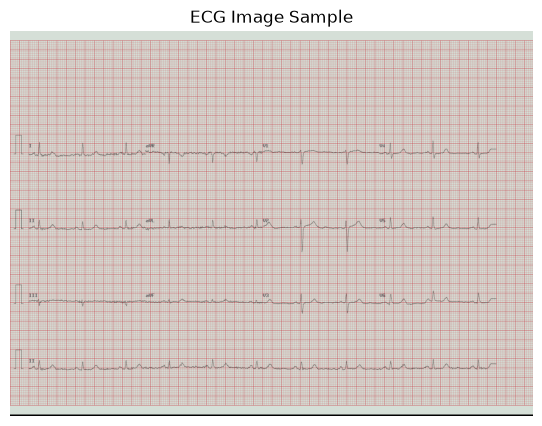

In [50]:
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Use the ECG image already downloaded from Hugging Face
image_path = Path(sample_path)

ecg_image = Image.open(image_path).convert("RGB")

print("Image size:", ecg_image.size)
print("Image mode:", ecg_image.mode)

plt.figure(figsize=(12, 5))
plt.imshow(ecg_image)
plt.axis("off")
plt.title("ECG Image Sample")
plt.show()

In [51]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"
ecg_folder.mkdir(parents=True, exist_ok=True)

image_path = Path(sample_path)

if image_path.exists():
    destination = ecg_folder / "sample_ecg.png"

    if image_path.resolve() != destination.resolve():
        import shutil
        shutil.copy2(image_path, destination)

    print("ECG sample saved successfully!")
    print("Saved at:", destination)
else:
    print("Sample image path not found. Please check the previous download cell.")

ECG sample saved successfully!
Saved at: C:\Users\JV\Desktop\data\ecg_images\sample_ecg.png


In [52]:
import pandas as pd
import ast
from pathlib import Path

csv_path = Path.home() / "Desktop" / "data" / "ptbxl_database.csv"
ptbxl_df = pd.read_csv(csv_path)

sample_name = Path(sample_path).name
record_id = int(sample_name.split("_")[0])

matching_record = ptbxl_df[ptbxl_df["ecg_id"] == record_id]

if not matching_record.empty:
    row = matching_record.iloc[0]
    codes = ast.literal_eval(row["scp_codes"]) if isinstance(row["scp_codes"], str) else {}

    print("ECG record ID:", record_id)
    print("Record found in PTB-XL metadata!")
    print("Diagnostic annotation codes:", codes)
else:
    print("No matching record found for ID:", record_id)
    print("We need to verify the image-to-record mapping before assigning labels.")

ECG record ID: 1
Record found in PTB-XL metadata!
Diagnostic annotation codes: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}


In [53]:
from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path
import shutil

repo_id = "akshithamuthyalampally/GenECG"
api = HfApi()

ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"
ecg_folder.mkdir(parents=True, exist_ok=True)

repo_files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

image_files = [
    f for f in repo_files
    if f.lower().endswith(".png")
    and "Dataset_A_ECGs_without_imperfections/" in f
]

print("Available ECG images:", len(image_files))
print("Example filenames:", image_files[:5])

Available ECG images: 128
Example filenames: ['Dataset_A_ECGs_without_imperfections/00000/00001_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00002_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00003_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00004_hr_1R.png', 'Dataset_A_ECGs_without_imperfections/00000/00005_hr_1R.png']


In [54]:
from huggingface_hub import hf_hub_download
from pathlib import Path
import shutil

repo_id = "akshithamuthyalampally/GenECG"
ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"
ecg_folder.mkdir(parents=True, exist_ok=True)

# Use the image filenames from the previous cell
sample_files = image_files[:30]
downloaded = 0

for filename in sample_files:
    try:
        downloaded_path = hf_hub_download(
            repo_id=repo_id,
            repo_type="dataset",
            filename=filename
        )

        destination = ecg_folder / Path(filename).name

        if not destination.exists():
            shutil.copy2(downloaded_path, destination)

        downloaded += 1
        print(f"{downloaded}/30 images prepared")

    except Exception as error:
        print("Skipped:", Path(filename).name, "-", str(error)[:150])

print("\nImages prepared:", downloaded)
print("Folder:", ecg_folder)

1/30 images prepared


Dataset_A_ECGs_without_imperfections/000(…): reconstructing file:   0%|          |  0.00B /  111kB            

Dataset_A_ECGs_without_imperfections/000(…): downloading bytes:           |  0.00B            

2/30 images prepared


Dataset_A_ECGs_without_imperfections/000(…): reconstructing file:   0%|          |  0.00B /  103kB            

...

Dataset_A_ECGs_without_imperfections/000(…): downloading bytes:           |  0.00B            

29/30 images prepared


Dataset_A_ECGs_without_imperfections/000(…): reconstructing file:   0%|          |  0.00B /  121kB            

Dataset_A_ECGs_without_imperfections/000(…): downloading bytes:           |  0.00B            

30/30 images prepared

Images prepared: 30
Folder: C:\Users\JV\Desktop\data\ecg_images


In [55]:
from pathlib import Path
from PIL import Image

ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"

image_files_local = list(ecg_folder.glob("*.png"))

print("Total ECG images found:", len(image_files_local))

valid_images = 0

for file in image_files_local:
    try:
        with Image.open(file) as img:
            img.verify()
        valid_images += 1
    except Exception:
        print("Could not open:", file.name)

print("Valid images:", valid_images)

Total ECG images found: 31
Valid images: 31


In [56]:
import pandas as pd
import ast
from pathlib import Path

csv_path = Path.home() / "Desktop" / "data" / "ptbxl_database.csv"
ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"

ptbxl_df = pd.read_csv(csv_path)
ptbxl_df["ecg_id"] = pd.to_numeric(ptbxl_df["ecg_id"], errors="coerce")

records = []

for image_path in ecg_folder.glob("*.png"):
    try:
        record_id = int(image_path.name.split("_")[0])
    except ValueError:
        continue

    match = ptbxl_df[ptbxl_df["ecg_id"] == record_id]

    if not match.empty:
        codes = match.iloc[0]["scp_codes"]
        if isinstance(codes, str):
            codes = ast.literal_eval(codes)

        records.append({
            "image": image_path.name,
            "ecg_id": record_id,
            "diagnostic_codes": str(codes)
        })

matched_df = pd.DataFrame(records)
print("Images matched to PTB-XL records:", len(matched_df))
display(matched_df.head(10))

Images matched to PTB-XL records: 30


,image,ecg_id,diagnostic_codes
0,00001_hr_1R.png,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,00002_hr_1R.png,2,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,00003_hr_1R.png,3,"{'NORM': 100.0, 'SR': 0.0}"
3,00004_hr_1R.png,4,"{'NORM': 100.0, 'SR': 0.0}"
4,00005_hr_1R.png,5,"{'NORM': 100.0, 'SR': 0.0}"
5,00006_hr_1R.png,6,"{'NORM': 100.0, 'SR': 0.0}"
6,00007_hr_1R.png,7,"{'NORM': 100.0, 'SR': 0.0}"
7,00008_hr_1R.png,8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}"
8,00009_hr_1R.png,9,"{'NORM': 100.0, 'SR': 0.0}"
9,00010_hr_1R.png,10,"{'NORM': 100.0, 'SR': 0.0}"


In [57]:
from collections import Counter
import ast

if matched_df.empty:
    print("No matching records found.")
    print("Stop here: we need to verify the image-to-record mapping first.")
else:
    code_counts = Counter()

    for codes_text in matched_df["diagnostic_codes"]:
        codes = ast.literal_eval(codes_text)
        code_counts.update(codes.keys())

    print("Diagnostic codes found in matched records:")
    for code, count in code_counts.most_common():
        print(f"{code}: {count}")

Diagnostic codes found in matched records:
SR: 22
NORM: 21
AFLT: 4
ABQRS: 3
SBRAD: 2
SARRH: 2
NST_: 2
DIG: 2
LVOLT: 1
IMI: 1
AFIB: 1
NDT: 1
LVH: 1


In [58]:
import ast
import pandas as pd

if matched_df.empty:
    print("No matched records available. We cannot create labels safely yet.")
else:
    labeled_df = matched_df.copy()

    def has_norm_annotation(codes_text):
        codes = ast.literal_eval(codes_text)
        return int("NORM" in codes)

    labeled_df["label"] = labeled_df["diagnostic_codes"].apply(
        has_norm_annotation
    )

    print("Labeled ECG images:", len(labeled_df))
    print("\nLabel counts:")
    print(labeled_df["label"].value_counts().sort_index())
    display(labeled_df.head())

Labeled ECG images: 30

Label counts:
label
0     9
1    21
Name: count, dtype: int64


,image,ecg_id,diagnostic_codes,label
0,00001_hr_1R.png,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",1
1,00002_hr_1R.png,2,"{'NORM': 80.0, 'SBRAD': 0.0}",1
2,00003_hr_1R.png,3,"{'NORM': 100.0, 'SR': 0.0}",1
3,00004_hr_1R.png,4,"{'NORM': 100.0, 'SR': 0.0}",1
4,00005_hr_1R.png,5,"{'NORM': 100.0, 'SR': 0.0}",1


In [59]:
from pathlib import Path
from PIL import Image

ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"

if "labeled_df" not in globals() or labeled_df.empty:
    print("No labeled ECG images are available yet.")
else:
    labeled_df = labeled_df[
        labeled_df["image"].apply(
            lambda name: (ecg_folder / name).exists()
        )
    ].copy()

    print("Usable labeled images:", len(labeled_df))
    print("\nImages per label:")
    print(labeled_df["label"].value_counts().sort_index())

    if labeled_df["label"].nunique() < 2:
        print("\nWe need verified examples from both groups before training.")
    elif labeled_df["label"].value_counts().min() < 5:
        print("\nToo few examples in at least one group. We should collect more.")
    else:
        print("\nBoth groups have examples. We can prepare a small prototype.")

Usable labeled images: 30

Images per label:
label
0     9
1    21
Name: count, dtype: int64

Both groups have examples. We can prepare a small prototype.


In [60]:
import numpy as np
from PIL import Image
from pathlib import Path

ecg_folder = Path.home() / "Desktop" / "data" / "ecg_images"

if "labeled_df" not in globals() or labeled_df.empty:
    raise ValueError(
        "The labeled dataset is empty. We need to resolve the image-label mapping first."
    )

X_images = []
y_labels = []

for _, row in labeled_df.iterrows():
    image_path = ecg_folder / row["image"]

    if image_path.exists():
        with Image.open(image_path) as img:
            img = img.convert("RGB").resize((128, 128))
            X_images.append(np.asarray(img, dtype=np.float32) / 255.0)
            y_labels.append(int(row["label"]))

X_images = np.array(X_images, dtype=np.float32)
y_labels = np.array(y_labels, dtype=np.int64)

print("Training images array:", X_images.shape)
print("Labels array:", y_labels.shape)

Training images array: (30, 128, 128, 3)
Labels array: (30,)


In [62]:
%pip install tensorflow

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 3.7/384.1 MB 19.5 MB/s eta 0:00:20
    --------------------------------------- 6.6/384.1 MB 15.9 MB/s eta 0:00:24
    --------------------------------------- 8.1/384.1 MB 15.3 MB/s eta 0:00:25
   - -------------------------------------- 11.0/384.1 MB 13.6 MB/s eta 0:00:28
   - -------------------------------------- 13.6/384.1 MB 13.3 MB/s eta 0:00:28
   - -------------------------------------- 16.5/384.1 MB 13.3 MB/s eta 0:00:28
   -- ------------------------------------- 19.4/384.1 MB 13.4 MB/s eta 0:00:28
   -- ------------------------------------- 22.5/384.1 MB 13.5 MB/s eta 0:00:27
   -- ------------------------------------- 25.7/384.1 MB 13.6 MB/s eta 0:00:27
   -- ------------------------------------- 28.0/384.1 MB 13.4 MB/s eta 0:00:27
   --- ------------------------------------ 29.9/384.1 MB 13.0 MB/s eta 0:00:28
   --- ------------------------------------ 32.0/384

In [63]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Ensure the arrays were created in the previous step
if len(X_images) < 20 or len(np.unique(y_labels)) < 2:
    raise ValueError(
        "Not enough images or only one label class. "
        "We need more correctly labeled examples before training."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X_images,
    y_labels,
    test_size=0.2,
    random_state=42,
    stratify=y_labels
)

model = Sequential([
    Input(shape=(128, 128, 3)),
    Conv2D(16, 3, activation="relu"),
    MaxPooling2D(),
    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=8,
    batch_size=8,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1
)

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Experimental test accuracy: {test_accuracy:.2%}")
print(classification_report(
    y_test,
    (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int),
    zero_division=0
))

ImportError: DLL load failed while importing _proto_comparators: An Application Control policy has blocked this file.

In [64]:
%pip show tensorflow

Name: tensorflow
Version: 2.22.0rc0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: C:\Users\JV\anaconda3\Lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras-nightly, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, six, termcolor, typing_extensions, wrapt
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [65]:
import tensorflow as tf
print(tf.__version__)

ValueError: The proto value '3' is already registered.

In [66]:
%pip show tensorflow tensorflow-cpu keras numpy

Name: tensorflow
Version: 2.22.0rc0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: C:\Users\JV\anaconda3\Lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras-nightly, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, six, termcolor, typing_extensions, wrapt
Required-by: 
---
Name: numpy
Version: 2.4.6
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License-Expression: BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0
Location: C:\Users\JV\anaconda3\Lib\site-packages
Requires: 
Required-by: astropy, bokeh, contourpy, datasets, datashader, gradio, h5py, holoviews, hvplot, ImageIO, imbalanced-learn, ipympl, keras-nightly, matplotlib, mkl_fft, mkl_random, ml_dtypes, numba, num

In [67]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu


In [68]:
import torch

print("PyTorch version:", torch.__version__)
print("CPU available:", True)

PyTorch version: 2.14.1+cpu
CPU available: True


In [69]:
import torch
import torch.nn as nn

class ECGImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

ecg_model = ECGImageClassifier()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(ecg_model.parameters(), lr=0.001)

print("ECG CNN created successfully!")
print("Model parameters:", sum(p.numel() for p in ecg_model.parameters()))

ECG CNN created successfully!
Model parameters: 23649


In [70]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np

# Confirm the prepared arrays exist
if "X_images" not in globals() or "y_labels" not in globals():
    raise ValueError(
        "X_images or y_labels is missing. Rerun the image-preparation cell first."
    )

if len(X_images) < 20 or len(np.unique(y_labels)) < 2:
    raise ValueError(
        "We need at least 20 images and examples from both label classes."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X_images, y_labels,
    test_size=0.2,
    random_state=42,
    stratify=y_labels
)

# Convert images from (N, H, W, C) to PyTorch's (N, C, H, W)
X_train_t = torch.tensor(
    X_train.transpose(0, 3, 1, 2), dtype=torch.float32
)
X_test_t = torch.tensor(
    X_test.transpose(0, 3, 1, 2), dtype=torch.float32
)
y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=8,
    shuffle=True
)

print("Training images:", len(X_train_t))
print("Testing images:", len(X_test_t))
print("Ready to train!")

Training images: 24
Testing images: 6
Ready to train!


In [71]:
from pathlib import Path

# Train the model
epochs = 8

for epoch in range(epochs):
    ecg_model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = ecg_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/{epochs} - Loss: {average_loss:.4f}")

# Save the trained model
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "ecg_image_classifier.pth"
torch.save(ecg_model.state_dict(), model_path)

print("\nTraining finished!")
print("Model saved at:", model_path.resolve())

Epoch 1/8 - Loss: 0.6622
Epoch 2/8 - Loss: 0.6392
Epoch 3/8 - Loss: 0.6241
Epoch 4/8 - Loss: 0.6053
Epoch 5/8 - Loss: 0.6043
Epoch 6/8 - Loss: 0.6063
Epoch 7/8 - Loss: 0.6095
Epoch 8/8 - Loss: 0.6121

Training finished!
Model saved at: C:\Users\JV\Desktop\models\ecg_image_classifier.pth


In [72]:
from sklearn.metrics import accuracy_score, classification_report

ecg_model.eval()

with torch.no_grad():
    logits = ecg_model(X_test_t)
    probabilities = torch.sigmoid(logits).squeeze(1).numpy()

predictions = (probabilities >= 0.5).astype(int)

print("Test accuracy:", f"{accuracy_score(y_test, predictions):.2%}")
print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

Test accuracy: 66.67%

Classification report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.67      1.00      0.80         4

    accuracy                           0.67         6
   macro avg       0.33      0.50      0.40         6
weighted avg       0.44      0.67      0.53         6



In [73]:
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
from PIL import Image

class ECGImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

ecg_model = ECGImageClassifier()
model_path = Path("models") / "ecg_image_classifier.pth"

ecg_model.load_state_dict(
    torch.load(model_path, map_location="cpu", weights_only=True)
)
ecg_model.eval()

def inspect_ecg_image(image):
    if image is None:
        return "Please upload an ECG image first."

    image_array = np.asarray(
        image.convert("RGB").resize((128, 128)),
        dtype=np.float32
    ) / 255.0

    image_tensor = torch.tensor(
        image_array.transpose(2, 0, 1),
        dtype=torch.float32
    ).unsqueeze(0)

    with torch.no_grad():
        probability = torch.sigmoid(ecg_model(image_tensor)).item()

    return (
        "Experimental model output\n"
        f"Score for label 1: {probability:.3f}\n\n"
        "This is an experimental score from a small training dataset, "
        "not a reliable normal/abnormal classification or medical diagnosis. "
        "Do not use it for medical decisions."
    )

print("ECG model loaded and image function updated!")

ECG model loaded and image function updated!


In [79]:
from pathlib import Path

requirements = """gradio
pandas
scikit-learn
joblib
google-genai
torch
numpy
Pillow
"""

requirements_path = Path("requirements.txt")
requirements_path.write_text(requirements, encoding="utf-8")

print("requirements.txt created at:")
print(requirements_path.resolve())
print("\nContents:\n")
print(requirements_path.read_text(encoding="utf-8"))

requirements.txt created at:
C:\Users\JV\Desktop\requirements.txt

Contents:

gradio
pandas
scikit-learn
joblib
google-genai
torch
numpy
Pillow



In [80]:
from pathlib import Path

project_folder = Path.cwd()
print("Current project folder:", project_folder)
print("Files in this folder:")

for item in project_folder.iterdir():
    print(item.name)

Current project folder: C:\Users\JV\Desktop
Files in this folder:
.git
.gradio
.ipynb_checkpoints
01_data_exploration.ipynb
Antigravity.lnk
Cisco Packet Tracer.lnk
data
desktop.ini
Eclipse IDE for Java Developers - 2026-09.lnk
EE Report.pdf
heart_health_chatbot
I AM
idt
IEEE-paper-FYP.docx
import matplotlib.docx
iot
models
MY 2026 HABIT TRACKER.xlsx
ptbxl_database.csv
requirements.txt
sucess.txt
suprajja.txt
Suupu.txt
Telegram.lnk
This PC - Shortcut.lnk
Visual Studio Code.lnk
vs python
win.txt


In [81]:
from pathlib import Path

app_file = Path("app.py")

if app_file.exists():
    print("app.py already exists at:", app_file.resolve())
    print("We should update it rather than overwrite it blindly.")
else:
    app_file.write_text(
        "# Heart Health Assistant\n"
        "# Deployment entry point for Hugging Face Spaces.\n",
        encoding="utf-8"
    )
    print("Created app.py at:", app_file.resolve())

Created app.py at: C:\Users\JV\Desktop\app.py


In [82]:
from pathlib import Path

ip = get_ipython()
history = ip.history_manager.input_hist_raw

matches = [
    (i, cell)
    for i, cell in enumerate(history)
    if 'with gr.Blocks(title="Heart Health Assistant") as app:' in cell
]

print("App code found in notebook history:", bool(matches))

if matches:
    print("App cell number:", matches[-1][0])
    print("We can use that cell to prepare app.py.")
else:
    print("The app cell was not found in notebook history.")

App code found in notebook history: True
App cell number: 82
We can use that cell to prepare app.py.


In [83]:
from pathlib import Path

ip = get_ipython()
history = ip.history_manager.input_hist_raw

matches = [
    cell for cell in history
    if 'with gr.Blocks(title="Heart Health Assistant") as app:' in cell
]

if not matches:
    print("App code not found in notebook history.")
    print("Keep your existing app cell; do not delete it.")
else:
    app_source = matches[-1]

    # Replace notebook-only API-key setup with a deployment secret.
    app_source = app_source.replace(
        "client = genai.Client(api_key=GEMINI_API_KEY)",
        'import os\n'
        'client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])'
    )

    app_path = Path("app.py")
    app_path.write_text(app_source, encoding="utf-8")

    print("Deployment file created:", app_path.resolve())
    print("File size:", app_path.stat().st_size, "bytes")

Deployment file created: C:\Users\JV\Desktop\app.py
File size: 884 bytes


In [84]:
from pathlib import Path

project_folder = Path.cwd()
models_folder = project_folder / "models"

required_files = [
    models_folder / "heart_disease_model.joblib",
    models_folder / "ecg_image_classifier.pth",
    project_folder / "app.py",
    project_folder / "requirements.txt",
]

print("Deployment file status:\n")

for file in required_files:
    status = "READY" if file.exists() else "MISSING"
    print(f"{status}: {file.relative_to(project_folder)}")

if all(file.exists() for file in required_files):
    print("\nAll required files are present.")
else:
    print("\nSome files are missing; we must resolve those before uploading.")

Deployment file status:

READY: models\heart_disease_model.joblib
READY: models\ecg_image_classifier.pth
READY: app.py
READY: requirements.txt

All required files are present.


In [3]:
%pip show gradio gradio-client

Name: gradio
Version: 6.30.0
Summary: Python library for easily interacting with trained machine learning models
Home-page: https://github.com/gradio-app/gradio
Author: 
Author-email: Abubakar Abid <gradio-team@huggingface.co>, Ali Abid <gradio-team@huggingface.co>, Ali Abdalla <gradio-team@huggingface.co>, Dawood Khan <gradio-team@huggingface.co>, Ahsen Khaliq <gradio-team@huggingface.co>, Pete Allen <gradio-team@huggingface.co>, Ömer Faruk Özdemir <gradio-team@huggingface.co>, Freddy A Boulton <gradio-team@huggingface.co>, Hannah Blair <gradio-team@huggingface.co>
License-Expression: Apache-2.0
Location: C:\Users\JV\anaconda3\Lib\site-packages
Requires: anyio, audioop-lts, brotli, fastapi, gradio-client, groovy, hf-gradio, httpx, huggingface-hub, jinja2, markupsafe, numpy, orjson, packaging, pandas, pillow, pydantic, pydub, python-multipart, pytz, pyyaml, safehttpx, semantic-version, starlette, tomlkit, typer, typing-extensions, uvicorn
Required-by: 
---
Name: gradio_client
Version: 

In [4]:
%pip install --upgrade gradio gradio-client

Note: you may need to restart the kernel to use updated packages.


In [1]:
import gradio as gr
print("Gradio version:", gr.__version__)

ImportError: DLL load failed while importing _compute: An Application Control policy has blocked this file.

In [2]:
%pip show gradio gradio-client gradio-simpletemplates simpledropdown simpleimage simpletextbox

Name: gradio
Version: 6.30.0
Summary: Python library for easily interacting with trained machine learning models
Home-page: https://github.com/gradio-app/gradio
Author: 
Author-email: Abubakar Abid <gradio-team@huggingface.co>, Ali Abid <gradio-team@huggingface.co>, Ali Abdalla <gradio-team@huggingface.co>, Dawood Khan <gradio-team@huggingface.co>, Ahsen Khaliq <gradio-team@huggingface.co>, Pete Allen <gradio-team@huggingface.co>, Ömer Faruk Özdemir <gradio-team@huggingface.co>, Freddy A Boulton <gradio-team@huggingface.co>, Hannah Blair <gradio-team@huggingface.co>
License-Expression: Apache-2.0
Location: C:\Users\JV\anaconda3\Lib\site-packages
Requires: anyio, audioop-lts, brotli, fastapi, gradio-client, groovy, hf-gradio, httpx, huggingface-hub, jinja2, markupsafe, numpy, orjson, packaging, pandas, pillow, pydantic, pydub, python-multipart, pytz, pyyaml, safehttpx, semantic-version, starlette, tomlkit, typer, typing-extensions, uvicorn
Required-by: 
---
Name: gradio_client
Version: 

In [3]:
import importlib.metadata as metadata

packages = [
    "gradio",
    "gradio-client",
    "gradio-simpletemplates",
    "simpledropdown",
    "simpleimage",
    "simpletextbox",
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

gradio: 6.30.0
gradio-client: 2.7.2
gradio-simpletemplates: NOT INSTALLED
simpledropdown: NOT INSTALLED
simpleimage: NOT INSTALLED
simpletextbox: NOT INSTALLED


In [4]:
import traceback

try:
    import gradio as gr
    print("Gradio imported successfully:", gr.__version__)
except Exception:
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\JV\AppData\Local\Temp\ipykernel_9368\3719625016.py", line 4, in <module>
    import gradio as gr
  File "C:\Users\JV\anaconda3\Lib\site-packages\gradio\__init__.py", line 3, in <module>
    import gradio._simple_templates
  File "C:\Users\JV\anaconda3\Lib\site-packages\gradio\_simple_templates\__init__.py", line 1, in <module>
    from .simpledropdown import SimpleDropdown
  File "C:\Users\JV\anaconda3\Lib\site-packages\gradio\_simple_templates\simpledropdown.py", line 7, in <module>
    from gradio.components.base import Component, FormComponent
  File "C:\Users\JV\anaconda3\Lib\site-packages\gradio\components\__init__.py", line 1, in <module>
    from gradio.components.annotated_image import AnnotatedImage
  File "C:\Users\JV\anaconda3\Lib\site-packages\gradio\components\annotated_image.py", line 15, in <module>
    from gradio.components.base import Component
  File "C:\Users\JV\anaconda3\Lib\site-packages\gradio\components\base.py

In [5]:
try:
    import pyarrow
    print("PyArrow loaded successfully:", pyarrow.__version__)
except Exception as e:
    print("PyArrow import failed:")
    print(type(e).__name__)
    print(e)

PyArrow loaded successfully: 26.0.0


In [6]:
try:
    import pyarrow
    print("PyArrow loaded successfully:", pyarrow.__version__)
except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", e)

PyArrow loaded successfully: 26.0.0


In [7]:
import pandas as pd
print("Pandas:", pd.__version__)

import pyarrow
print("PyArrow:", pyarrow.__version__)

import gradio as gr
print("Gradio:", gr.__version__)

ImportError: DLL load failed while importing _compute: An Application Control policy has blocked this file.

In [9]:
%pip install --force-reinstall "pandas==2.2.3" "pyarrow==19.0.1"

  Using cached pandas-2.2.3.tar.gz (4.4 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  Preparing metadata (pyproject.toml) did not run successfully.
  exit code: 1
  
  [12 lines of output]
  + meson setup C:\Users\JV\AppData\Local\Temp\pip-install-421t0zrz\pandas_4474bd99a70b4cf08468c7c9f169cc1d C:\Users\JV\AppData\Local\Temp\pip-install-421t0zrz\pandas_4474bd99a70b4cf08468c7c9f169cc1d\.mesonpy-twjdr2ly\build -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --vsenv --native-file=C:\Users\JV\AppData\Local\Temp\pip-install-421t0zrz\pandas_4474bd99a70b4cf08468c7c9f169cc1d\.mesonpy-twjdr2ly\build\meson-python-native-file.ini
  The Meson build system
  Version: 1.2.1
  Source dir: C:\Users\JV\AppData\Local\Temp\pip-install-421t0zrz\pandas_4474bd99a70b4cf08468c7c9f169cc1d
  Build dir: C:\Users\JV\AppData\Local\Temp\pip-install-421t0zrz\pandas_4474bd99a70b4cf08468c7c9f169cc1d\.mesonpy-twjdr2ly\build
  Build type: native build
  Project name: pandas
  Project version: 2.2.3
  
  ..\..\meson.build:2:0: ERROR: Could not parse vswhe

In [1]:
import pandas as pd
print("Pandas loaded:", pd.__version__)

ImportError: DLL load failed while importing _compute: An Application Control policy has blocked this file.

In [1]:
import sys

print("Python location:", sys.executable)

import pandas as pd
import gradio as gr
import joblib
from google import genai

print("Pandas:", pd.__version__)
print("Gradio:", gr.__version__)
print("All required imports succeeded!")

Python location: C:\Users\JV\anaconda3\envs\heartapp\python.exe


ImportError: DLL load failed while importing fields: An Application Control policy has blocked this file.

In [2]:
from pathlib import Path
import joblib

model_path = Path("models") / "heart_disease_model.joblib"

print("Notebook folder:", Path.cwd())
print("Model file found:", model_path.exists())

Notebook folder: C:\Users\JV\Desktop
Model file found: True


In [3]:
from pathlib import Path
import joblib

model_path = Path("models") / "heart_disease_model.joblib"
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)
print("Model file:", model_path.resolve())

AttributeError: partially initialized module 'pandas' has no attribute '_pandas_datetime_CAPI' (most likely due to a circular import)

In [4]:
import sys
import numpy as np
import sklearn
import joblib

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

AttributeError: partially initialized module 'pandas' has no attribute '_pandas_datetime_CAPI' (most likely due to a circular import)